In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
from scipy.optimize import curve_fit
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [3]:
# Deterministic logistic model 
def logistic_model(t, r, K, P0):
    P =  (K * P0 * np.exp(r * t)) / (K + P0 * (np.exp(r * t) - 1))
    return P 

# Linearized model
def log_logistic_model(t, r, K, P0):
    return np.log(logistic_model(t, r, K, P0))

def linearized_logistic_model(t, r, K, P0):
    P = logistic_model(t, r, K, P0)
    return np.log(P/(K-P))

In [4]:
# Load cleaned weekly U.S. COVID-19 data
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "troyc03/COVID19-Logistic-Growth-Project/main/"
    "data/processed/us_covid_clean.csv"
)

df = pd.read_csv(DATA_URL, parse_dates=["week_ending"])

# Only retain observations where case reporting was available
df = df.loc[df["cases_reported"].astype(bool)].copy()

df = df.sort_values("week_ending").reset_index(drop=True)

print(df.head())
print(f"\nNumber of observations: {len(df)}")
print(f"Date range: {df.week_ending.min()} to {df.week_ending.max()}")


  week_ending  total_cases  total_deaths  new_cases  new_deaths  week  \
0  2020-01-26            7             0        7.0         0.0     0   
1  2020-02-02            9             0        2.0         0.0     1   
2  2020-02-09           20             0       11.0         0.0     2   
3  2020-02-16           24             0        4.0         0.0     3   
4  2020-02-23           40             0       16.0         0.0     4   

   cases_reported  
0            True  
1            True  
2            True  
3            True  
4            True  

Number of observations: 173
Date range: 2020-01-26 00:00:00 to 2023-05-14 00:00:00


Selected observations: 35
Initial cases: 33,368,900
Final cases: 78,334,128


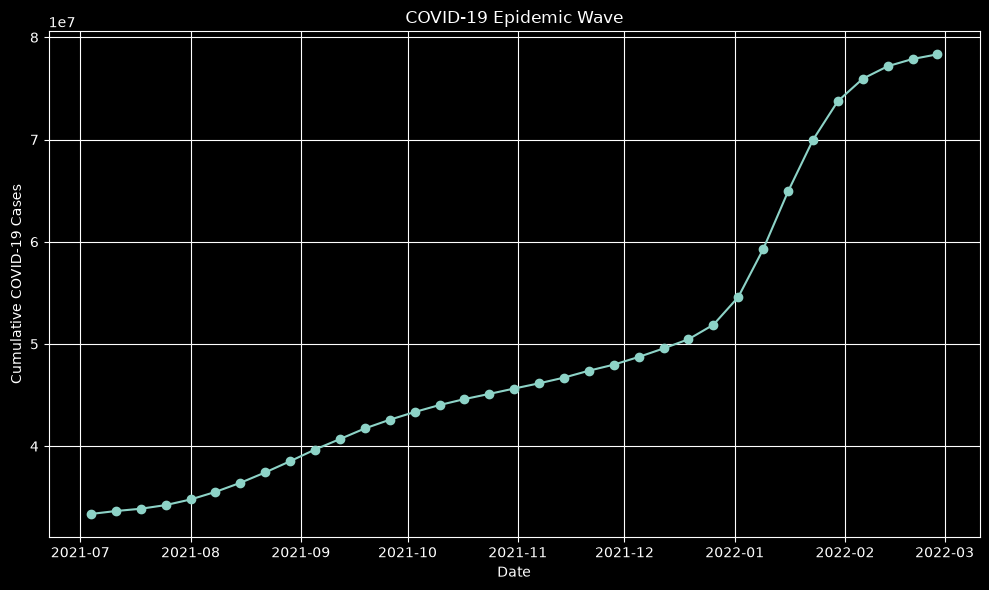

In [10]:
# EDIT THESE DATES TO SELECT YOUR EPIDEMIC WAVE

START_DATE = "2021-07-04"
END_DATE = "2022-02-27"

wave_df = df.loc[
    (df["week_ending"] >= START_DATE) &
    (df["week_ending"] <= END_DATE)
].copy()

wave_df = wave_df.reset_index(drop=True)

# Time measured in weeks from the first observation
t = np.arange(len(wave_df), dtype=float)

# Cumulative reported cases
P = wave_df["total_cases"].to_numpy(dtype=float)

if len(wave_df) < 8:
    raise ValueError("Select a wave containing at least 8 weekly observations.")

if np.any(np.diff(P) < 0):
    raise ValueError("Cumulative cases must be non-decreasing.")

P0 = P[0]

print(f"Selected observations: {len(P)}")
print(f"Initial cases: {P0:,.0f}")
print(f"Final cases: {P[-1]:,.0f}")

plt.style.use('dark_background')
plt.figure(figsize=(10, 6))
plt.plot(wave_df["week_ending"], P, "o-")

plt.xlabel("Date")
plt.ylabel("Cumulative COVID-19 Cases")
plt.title("COVID-19 Epidemic Wave")
plt.grid(True)
plt.tight_layout()
plt.show()


Linearized growth rate (r): 0.028877
Estimated carrying capacity (K): 391,670,640
Estimated initial population (P0): 30,725,365.98
Linearized R^2: 0.9271
Logistic R^2: 0.9130


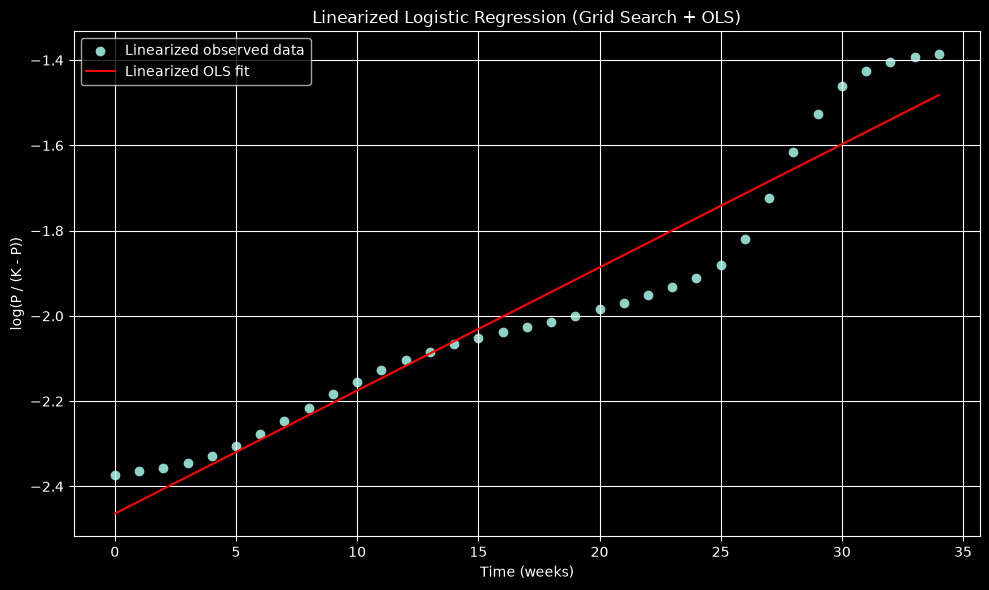

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from sklearn.metrics import r2_score

def logistic_model(t, r, K, P0):
    return K / (1.0 + ((K - P0) / P0) * np.exp(-r * t))

# 1. Grid search over K to maximize linear R^2
K_candidates = np.linspace(np.max(P) * 1.001, np.max(P) * 5.0, 2000)
best_r2 = -np.inf
best_K = None
best_slope = None
best_intercept = None

for K_cand in K_candidates:
    y_logit = np.log(P / (K_cand - P))
    slope, intercept, r_val, _, _ = linregress(t, y_logit)
    if r_val**2 > best_r2:
        best_r2 = r_val**2
        best_K = K_cand
        best_slope = slope
        best_intercept = intercept

# 2. Extract parameters and predictions
r_linear = best_slope
K_linear = best_K
# Note: intercept = log(P0_est / (K_linear - P0_est))
P0_est = K_linear / (1.0 + np.exp(-best_intercept))

linearized_P_obs = np.log(P / (K_linear - P))
linearized_P_pred = best_intercept + r_linear * t
P_linear = logistic_model(t, r_linear, K_linear, P0_est)

print(f"Linearized growth rate (r): {r_linear:.6f}")
print(f"Estimated carrying capacity (K): {K_linear:,.0f}")
print(f"Estimated initial population (P0): {P0_est:,.2f}")
print(f"Linearized R^2: {best_r2:.4f}")
print(f"Logistic R^2: {r2_score(P, P_linear):.4f}")

# 3. Plot the linear regression fit
plt.style.use('dark_background')
plt.figure(figsize=(10, 6))
plt.scatter(t, linearized_P_obs, label="Linearized observed data")
plt.plot(t, linearized_P_pred, color="red", label="Linearized OLS fit")
plt.xlabel("Time (weeks)")
plt.ylabel("log(P / (K - P))")
plt.title("Linearized Logistic Regression (Grid Search + OLS)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
